# 3D MMR modelling and inversion

Magnetometric resistivity (MMR): a current is injected in the ground with a pair of electrodes, and the
magnetic field of the current flowing in the ground is measured.  The field depends on the conductivity
contrasts, so its inversion gives the conductivity.

This notebook uses the same conductive prism, current dipoles and inversion grid as `example_dc.ipynb`, with
the three components of $\mathbf{B}$ measured at the surface.  It writes `data_mmr.dat`, used by the joint
inversion notebooks.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('..'))   # notebook run from the examples directory

from pymmr.finite_volume import calc_padding, GridFV
from pymmr.mmr import GridMMR
from pymmr.inversion import Inversion, DataMMR

## Grid

Cells of 60 m in a core region from −960 to 960 m in $x$ and $y$, and from −960 m to the surface in $z$,
with 10 padding cells on the sides and at the bottom.  `GridMMR` adds air layers above the ground: the
magnetic field is computed from the current density in the earth, but the observation points are at the surface.

In [2]:
x = np.arange(-60.0 * 16, 60.01 * 16, 60)
y = np.arange(-60.0 * 16, 60.01 * 16, 60)
z = np.arange(-60.0 * 16, 0.01, 60)

pad = np.cumsum(calc_padding(60.0, 10))

x = np.r_[x[0] - pad[::-1], x, x[-1] + pad]
y = np.r_[y[0] - pad[::-1], y, y[-1] + pad]
z = np.r_[z[0] - pad, z]

g = GridMMR((x, y, z))
g.verbose = True
g.set_solver("mumps")

## Survey

The two current dipoles of `example_dc.ipynb` (1200 m, along $x$ and along $y$).  For each source, $B_x$, $B_y$ and
$B_z$ are measured at 26 × 26 stations from −400 to 400 m (32 m spacing) at the surface.  As in the DC example,
a few rows are removed and some are swapped.

`set_survey_mmr` takes one row per station: the coordinates of the source electrodes (`xs`), of the station
(`xo`), and the current (`cs`, in A).  With `apply_bc = True`, the error at the electrodes, where the potential is
singular, is reduced with the analytic primary field (boundary correction).

In [3]:
c1c2 = np.array(
    [[-600.0, 0.0, 0.0, 600.0, 0.0, 0.0], [0.0, -600.0, 0.0, 0.0, 600.0, 0.0]]
)

xo = np.linspace(-400, 400, 26)
yo = np.linspace(-400, 400, 26)
xo = np.c_[
    np.kron(xo.reshape(-1, 1), np.ones((yo.size, 1))),
    np.kron(np.ones((xo.size, 1)), yo.reshape(-1, 1)),
    np.zeros((xo.size * yo.size, 1)),
]

tmp = np.kron(c1c2, np.ones((xo.shape[0], 1)))
xo = np.kron(np.ones((c1c2.shape[0], 1)), xo)
c1c2 = tmp

# remove some points
mask = np.ones((xo.shape[0],), dtype=bool)
mask[5] = False
mask[200] = False
mask[-1] = False
c1c2 = c1c2[mask, :]
xo = xo[mask, :]

# change order
ind = np.arange(xo.shape[0])
ind[7] = 322
ind[322] = 7
ind[500] = 14
ind[14] = 500
c1c2 = c1c2[ind, :]
xo = xo[ind, :]

g.set_survey_mmr(xs=c1c2, xo=xo, cs=1.0)
g.apply_bc = True

## True model

A conductive prism, 0.1 S/m (10 Ω·m), 400 m × 400 m in plan ($|x|, |y| < 200$ m) and from 80 to 480 m depth,
in a 0.001 S/m (1000 Ω·m) half-space.

In [4]:
sigma = 0.001 + np.zeros((g.dc.nc,))

ix = np.where(np.logical_and(g.fv.xc > -200, g.fv.xc < 200))[0]
iy = np.where(np.logical_and(g.fv.yc > -200, g.fv.yc < 200))[0]
iz = np.where(np.logical_and(g.dc.fv.zc < -80, g.dc.fv.zc > -480))[0]
sigma[g.dc.fv.ind(ix, iy, iz)] = 0.1

## Synthetic data

`fwd_mod` returns $B_x$, $B_y$ and $B_z$ in pT (the default unit of `GridMMR`), for each station.  The data are
written to `data_mmr.dat`.

In [5]:
dobs1 = g.fwd_mod(sigma)

filename = "data_mmr.dat"
header = "c1_x c1_y c1_z c2_x c2_y c2_z obs_x obs_y obs_z Bx By Bz cs"
np.savetxt(filename, np.c_[c1c2, xo, dobs1, np.ones((dobs1.shape[0],))], header=header, fmt="%g")


Forward modelling - Magnetometric resistivity
    Grid: 52 x 52 x 26 voxels
      X min: -4.284321e+03	X max: 4.284321e+03
      Y min: -4.284321e+03	Y max: 4.284321e+03
      Z min: -4.284321e+03	Z max: 0.000000e+00
    Solver: MUMPS
  Computing interpolation matrices ... 

done.
  Computing current density ... 

done.
  Solving MMR system


      Memory footprint of A : 50.07 MB


End of modelling.


The data are put in a `DataMMR`, with errors (`wt`, in %) of 1 % for each component.  Remove the comment on the
first line and use `dobs` to add Gaussian noise (standard deviation 0.03 pT).

In [6]:
# dobs = dobs1 + np.random.default_rng().normal(0.0, 0.03, dobs1.shape)

# data_mmr = DataMMR(xs=c1c2, xo=xo, data=dobs, wt=np.ones((3*dobs.shape[0],)), cs=1.0, date=None)
data_mmr = DataMMR(xs=c1c2, xo=xo, data=dobs1, wt=np.ones((3*dobs1.shape[0],)), cs=1.0, date=None)

## Inversion

Gauss-Newton inversion of the three components for $\ln\sigma$, with the default smoothness regularization:

- starting and reference model: the 1000 Ω·m half-space;
- smoothness weights `alx`, `aly`, `alz` = 0.5;
- $\beta$ from 2500, divided by 2 at each iteration down to 100;
- 5 iterations;
- only the cells of the region of interest ($|x|, |y| \le 400$ m) are inverted.

The models of the iterations are written to `example_mmr.vtr`.

MMR data are not sensitive to a uniform scaling of the conductivity (the current density does not change);
they only see contrasts.  The absolute level of the model comes from the reference model.


Inversion
    Grid: 52 x 52 x 26 voxels
      X min: -4.284321e+03	X max: 4.284321e+03
      Y min: -4.284321e+03	Y max: 4.284321e+03
      Z min: -4.284321e+03	Z max: 0.000000e+00
    Region of interest:
      X min: -4.000000e+02	X max: 4.000000e+02
      Y min: -4.000000e+02	Y max: 4.000000e+02
      Z min: -9.600000e+02	Z max: 0.000000e+00
    Number of parameters to estimate: 3136
    Number of MMR data: 4047
    Algorithm: Gauss-Newton
    Maximum number of iterations: 5
    Working variable: log_conductivity
    Type of smoothing: smooth
      Smoothing factor along x: 0.5
      Smoothing factor along y: 0.5
      Smoothing factor along z: 0.5
      Smallness factor: 0.01
    Regularization variable: model
    Regularization β: 2500
      Cooling factor: 2
      Min value: 100
    Data weighting: variance
      error floor 𝜖: 0.1
    Model weighting: distance
      Distance weighting β: 0.5
    cglscd: preconditioner regularization, tol 1e-09, max_it auto
    Conductivity bound

  ------------------------------------------------------------
  *** Iteration no 1 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 9.94806, misfit: 0.139857, smy: 0
    Computing perturbation with cglscd ... 

    Factorizing regularization matrix ... 

done.


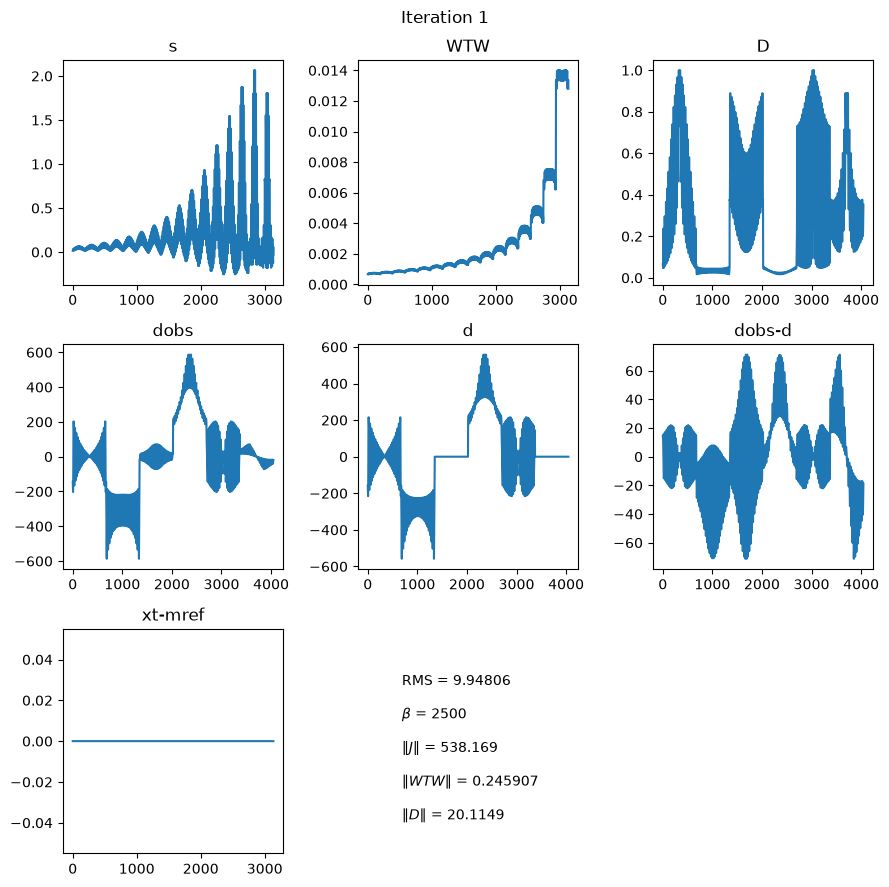

<Figure size 640x480 with 0 Axes>

done.
      err = 9.256056e-10, iter = 60
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
  *** Iteration no 2 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 1.18393, misfit: 0.0163436, smy: 445.655
    Computing perturbation with cglscd ... 

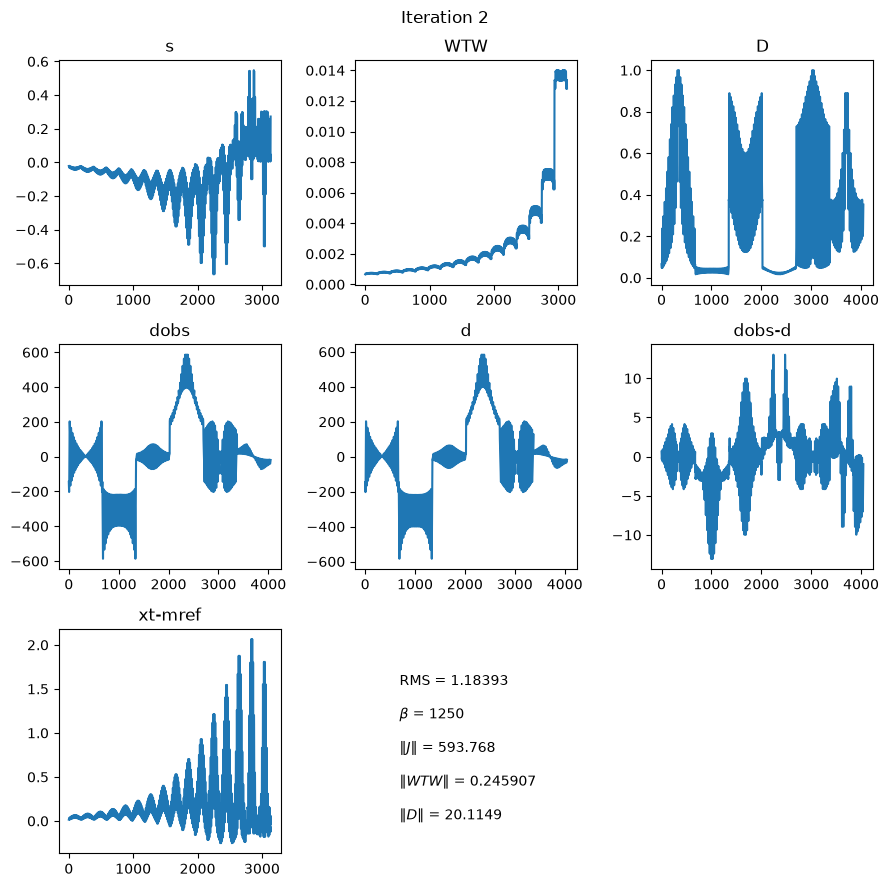

<Figure size 640x480 with 0 Axes>

done.
      err = 9.261252e-10, iter = 97
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
  *** Iteration no 3 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 0.738204, misfit: 0.0103233, smy: 79.7088
    Computing perturbation with cglscd ... 

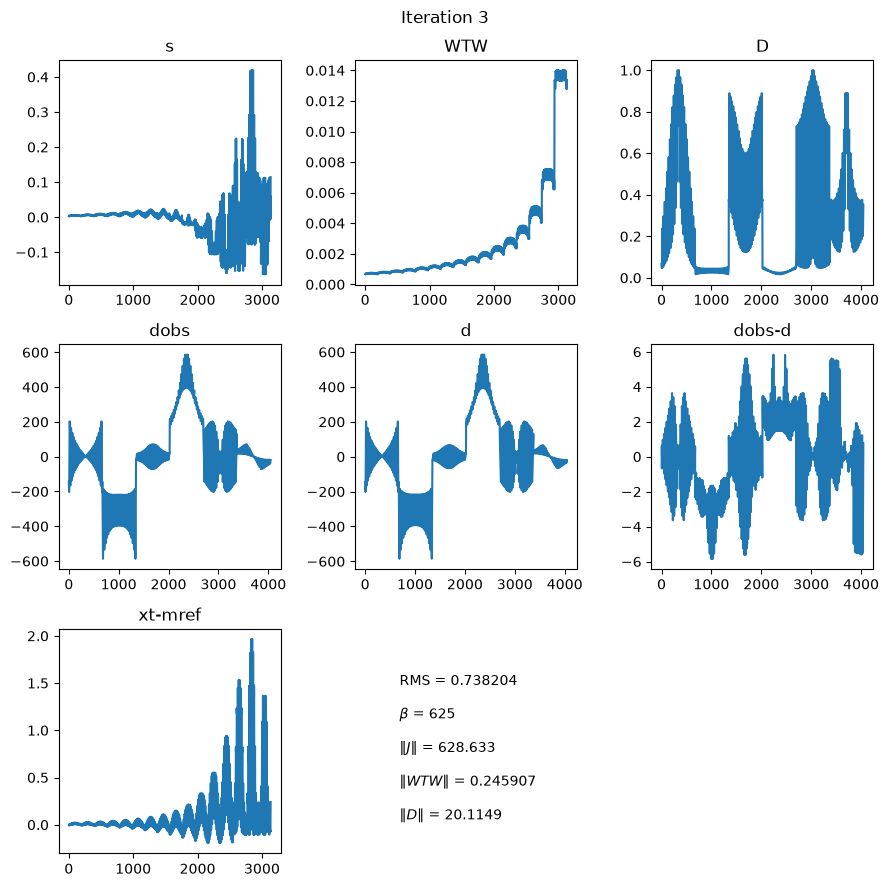

<Figure size 640x480 with 0 Axes>

done.
      err = 4.875745e-10, iter = 148
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
  *** Iteration no 4 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 0.505769, misfit: 0.00815745, smy: 11.087
    Computing perturbation with cglscd ... 

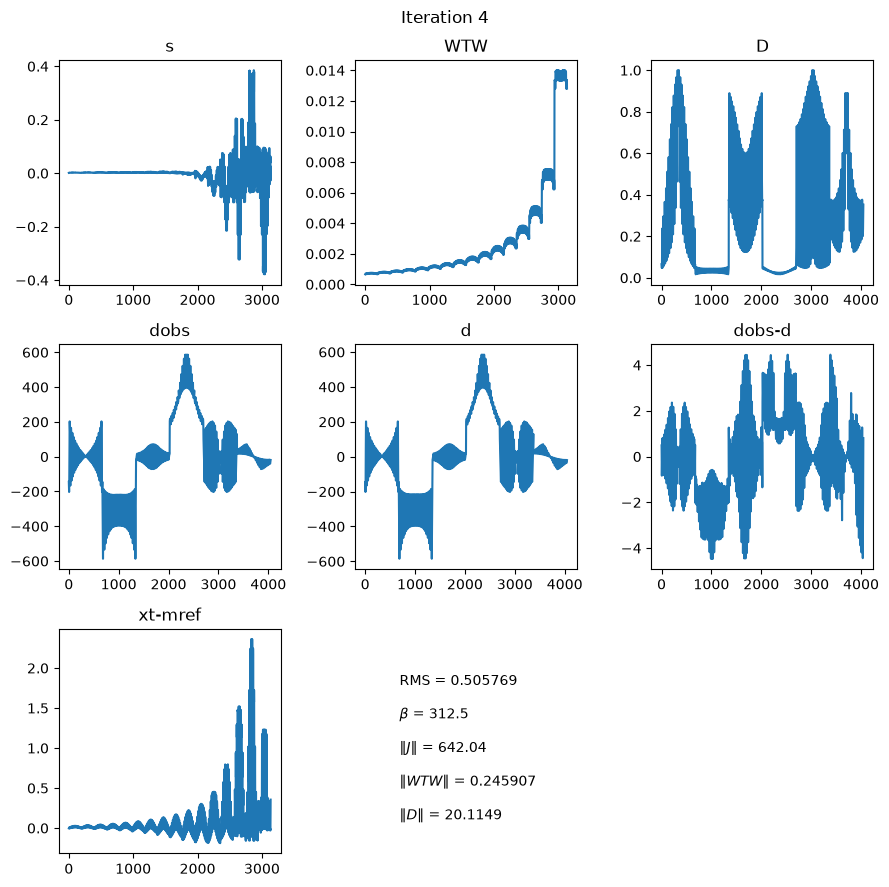

<Figure size 640x480 with 0 Axes>

done.
      err = 6.430235e-10, iter = 212
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
  *** Iteration no 5 ***
    Forward modelling & computation of jacobian ... 

done.
    Weighted RMS: 0.393465, misfit: 0.00683086, smy: 12.1271
    Computing perturbation with cglscd ... 

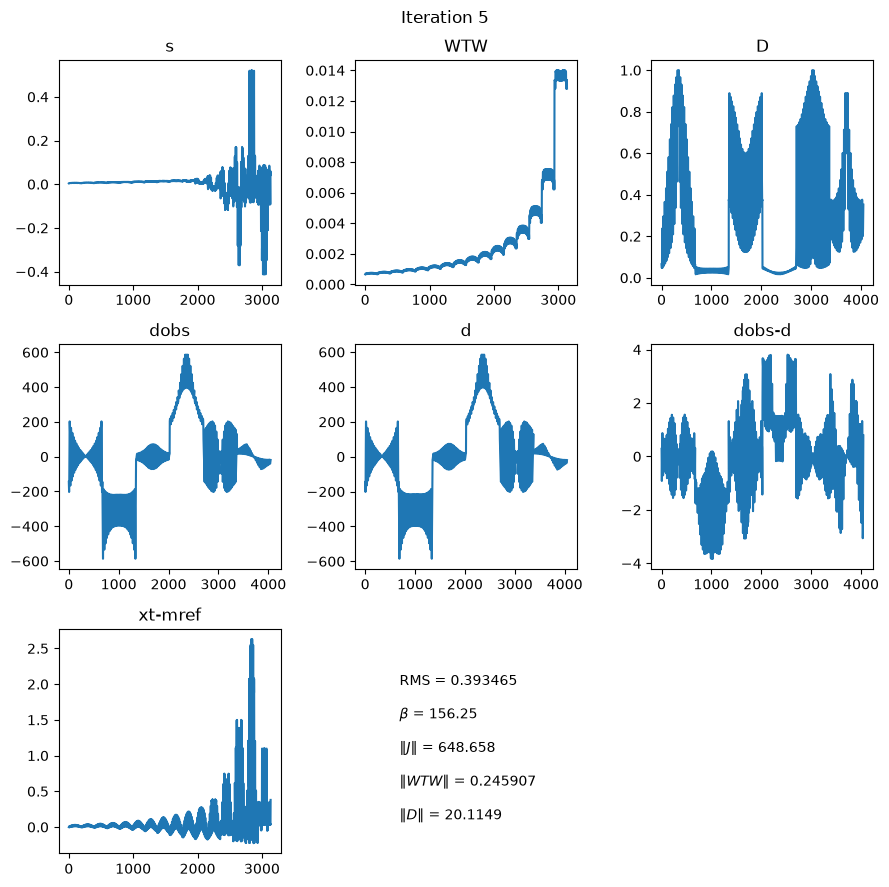

<Figure size 640x480 with 0 Axes>

done.
      err = 6.568327e-10, iter = 282
    Computing step length (parabolic line search)
      Forward modelling ... 

done.
      Forward modelling ... 

done.
  ------------------------------------------------------------
End of inversion.


In [7]:
inv = Inversion()
inv.max_it = 5
inv.alx = 0.5
inv.aly = 0.5
inv.alz = 0.5
inv.beta = 2500
inv.beta_min = 100
inv.show_plots = True

m_ref = 0.001 + np.zeros((g.dc.nc,))

g.set_roi([-400, 400, -400, 400, -960, 0])
g.verbose = False

results = inv.run(g, m0=m_ref, m_ref=m_ref, data_mmr=data_mmr, m_active=g.ind_roi)

sigma_inv, data_inv, rms, misfit, smy = results

x, y, z = g.dc.get_roi_nodes()
g2 = GridFV((x, y, z))

fields = {}
for n, sigma in enumerate(sigma_inv):
    name = 'iteration {0:d}'.format(n+1)
    fields[name] = sigma

g2.toVTK(fields, "example_mmr")

## Misfit

Data misfit (RMSE weighted by the data errors) at each iteration.

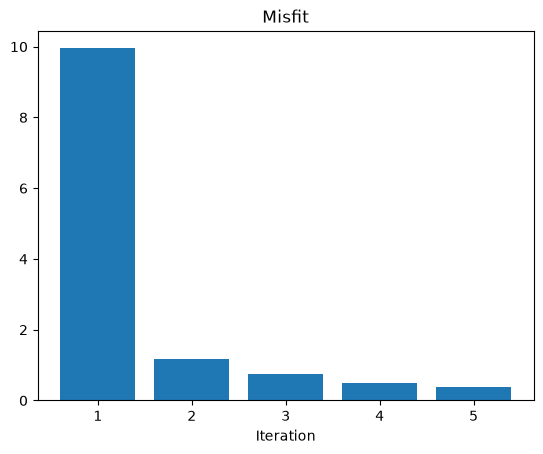

In [8]:
plt.figure()
plt.bar(np.arange(1, 1+len(rms)), rms)
plt.xlabel('Iteration')
plt.title('Misfit')
plt.show()